# Análisis de redes con PageRank, HITS y PageRank sensible a tópico

**Instrucción:** utilizar los diferentes datasets y analizarlos con HITS, PageRank y PageRank sensible a tópico.

| | Dataset | Tipo de red | Nodos | Aristas |
|---|---|---|---|---|
| **Parte I** | *Spotify Artist Feature Collaboration Network* (Kaggle) | No dirigida (colaboraciones) | ~156 mil artistas | ~300 mil |
| **Parte II** | *High-energy physics citation network* (SNAP, `cit-HepPh`) | Dirigida (citas) | ~34.5 mil artículos | ~421 mil |

Cada parte sigue el mismo procedimiento: **1** carga y limpieza → **2** PageRank → **3** HITS → **4** PageRank sensible a tópico → **5** conclusiones. Al final se comparan ambas redes.

#  I. Red de colaboraciones de Spotify

## Equipo:
- Angel Noel Perez Martinez
- Isaac Monroy Villegas
- Valentina Ayelen Cruz Mendoza 

**Dataset:** *Spotify Artist Feature Collaboration Network* (Kaggle).
- `nodes.csv`: artistas (`spotify_id, name, followers, popularity, genres, chart_hits`)
- `edges.csv`: colaboraciones entre dos artistas (`id_0, id_1`)

**Objetivo:** identificar a los artistas más importantes de la red con tres algoritmos de análisis de enlaces y comparar sus resultados entre sí y con las métricas propias de Spotify (seguidores y popularidad).

In [1]:
import ast
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

pd.set_option('display.max_colwidth', 60)
plt.rcParams['figure.dpi'] = 110

## I.1. Carga y limpieza de datos

In [2]:
nodes = pd.read_csv('nodes.csv')
edges = pd.read_csv('edges.csv')
print('Nodos crudos:', len(nodes), '| Aristas crudas:', len(edges))

# genres / chart_hits vienen como texto "['a', 'b']" -> listas reales
nodes['genres'] = nodes['genres'].apply(ast.literal_eval)
nodes['chart_hits'] = nodes['chart_hits'].fillna('[]').apply(ast.literal_eval)

# Hay spotify_id duplicados: nos quedamos con el registro de más seguidores
nodes = (nodes.sort_values('followers', ascending=False)
              .drop_duplicates('spotify_id')
              .set_index('spotify_id'))
nodes['name'] = nodes['name'].fillna('(sin nombre)')
nodes['followers'] = nodes['followers'].fillna(0)

# Aristas: quitar auto-loops, IDs inexistentes y duplicados (A-B == B-A)
edges = edges[(edges.id_0 != edges.id_1)
              & edges.id_0.isin(nodes.index) & edges.id_1.isin(nodes.index)]
edges = pd.DataFrame(np.sort(edges.values, axis=1), columns=['id_0', 'id_1']).drop_duplicates()
print('Nodos limpios:', len(nodes), '| Aristas limpias:', len(edges))
nodes.head()

Nodos crudos: 156422 | Aristas crudas: 300386
Nodos limpios: 156320 | Aristas limpias: 300379


,name,followers,popularity,genres,chart_hits
spotify_id,,,,,
6eUKZXaKkcviH0Ku9w2n3V,Ed Sheeran,102156853.0,90,"[pop, uk pop]","[us (52), gb (83), ar (36), au (65), at (59), be (58), b..."
66CXWjxzNUsdJxJ2JdwvnR,Ariana Grande,83045090.0,88,"[dance pop, pop]","[us (81), gb (69), ar (36), au (70), at (43), be (61), b..."
6qqNVTkY8uBg9cP3Jd7DAH,Billie Eilish,68407227.0,88,"[art pop, electropop, pop]","[us (46), gb (43), ar (23), au (45), at (42), be (43), b..."
3TVXtAsR1Inumwj472S9r4,Drake,66852536.0,95,"[canadian hip hop, canadian pop, hip hop, rap, toronto rap]","[us (190), gb (163), ar (18), au (148), at (97), be (99)..."
1uNFoZAHBGtllmzznpCI3s,Justin Bieber,65590075.0,90,"[canadian pop, pop]","[us (58), gb (51), ar (29), au (54), at (44), be (46), b..."


### Construcción del grafo y estadísticas básicas

In [3]:
G = nx.Graph()
G.add_nodes_from(nodes.index)
G.add_edges_from(edges.itertuples(index=False, name=None))

grados = pd.Series(dict(G.degree()))
comps = sorted(nx.connected_components(G), key=len, reverse=True)
print(f'Nodos: {G.number_of_nodes():,}  Aristas: {G.number_of_edges():,}')
print(f'Grado promedio: {grados.mean():.2f}  Grado máximo: {grados.max()}')
print(f'Nodos aislados (sin colaboraciones): {(grados == 0).sum():,}')
print(f'Componentes conexas: {len(comps):,}  Componente gigante: {len(comps[0]):,} nodos '
      f'({len(comps[0]) / G.number_of_nodes():.1%})')

nodes['grado'] = grados
nodes.sort_values('grado', ascending=False)[['name', 'grado', 'followers', 'popularity']].head(10)

Nodos: 156,320  Aristas: 300,379
Grado promedio: 3.84  Grado máximo: 1781
Nodos aislados (sin colaboraciones): 2,999
Componentes conexas: 4,338  Componente gigante: 148,380 nodos (94.9%)


,name,grado,followers,popularity
spotify_id,,,,
5aIqB5nVVvmFsvSdExz408,Johann Sebastian Bach,1781,3701532.0,75
1U5zgr455OGyIkLNXvDdrf,Traditional,1371,49046.0,59
0f1IECbrVV952unZkzrsg2,Mc Gw,858,1448741.0,66
4hV3aU0WKvFaiX5ugXP5hp,MC MN,632,32119.0,46
7jzR5qj8vFnSu5JHaXgFEr,Jean Sibelius,580,194098.0,56
0SfsnGyD8FpIN4U4WCkBZ5,Armin van Buuren,513,4094260.0,74
13y7CgLHjMVRMDqxdx0Xdo,Gucci Mane,509,4454550.0,77
77AiFEVeAVj2ORpC85QVJs,Steve Aoki,498,3689746.0,74
7hJcb9fa4alzcOq3EaNPoG,Snoop Dogg,495,8686870.0,84


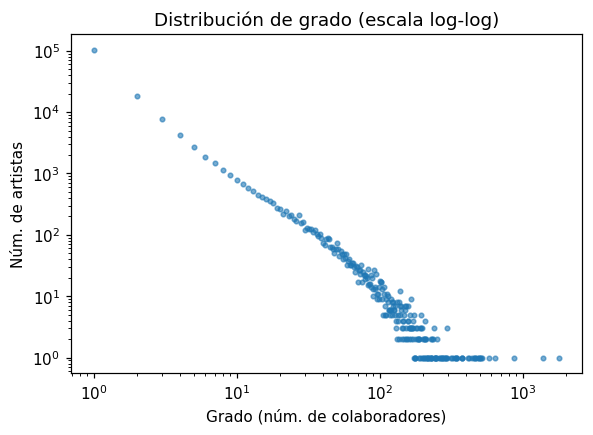

In [4]:
fig, ax = plt.subplots(figsize=(6, 4))
cnt = grados[grados > 0].value_counts().sort_index()
ax.loglog(cnt.index, cnt.values, '.', alpha=.6)
ax.set(xlabel='Grado (núm. de colaboradores)', ylabel='Núm. de artistas',
       title='Distribución de grado (escala log-log)')
plt.show()

La distribución sigue aproximadamente una **ley de potencias**: la mayoría de los artistas colabora con muy pocos y unos cuantos funcionan como *hubs* con cientos de colaboraciones. Es una red libre de escala típica.

## I.2. PageRank

PageRank modela a un *surfista aleatorio* que salta de artista en artista siguiendo colaboraciones, y con probabilidad `1 - α` (α = 0.85) se teletransporta a un artista al azar. Un artista es importante si colabora con artistas que a su vez son importantes.

In [5]:
pr = nx.pagerank(G, alpha=0.85)
nodes['pagerank'] = pd.Series(pr)

def top(col, n=20, extra=()):
    return nodes.nlargest(n, col)[['name', col, 'grado', 'followers', 'popularity', *extra]]

top('pagerank')

,name,pagerank,grado,followers,popularity
spotify_id,,,,,
5aIqB5nVVvmFsvSdExz408,Johann Sebastian Bach,0.003733,1781,3701532.0,75
1U5zgr455OGyIkLNXvDdrf,Traditional,0.002852,1371,49046.0,59
7jzR5qj8vFnSu5JHaXgFEr,Jean Sibelius,0.001136,580,194098.0,56
0f1IECbrVV952unZkzrsg2,Mc Gw,0.001031,858,1448741.0,66
4hV3aU0WKvFaiX5ugXP5hp,MC MN,0.000812,632,32119.0,46
5vzETUgvElb2xfKJ1e0VHN,הכוכב הבא,0.000787,377,24901.0,48
3dRfiJ2650SZu6GbydcHNb,John Williams,0.000748,415,1154733.0,70
1mYsTxnqsietFxj1OgoGbG,A.R. Rahman,0.000670,463,23828027.0,79
0SfsnGyD8FpIN4U4WCkBZ5,Armin van Buuren,0.000655,513,4094260.0,74


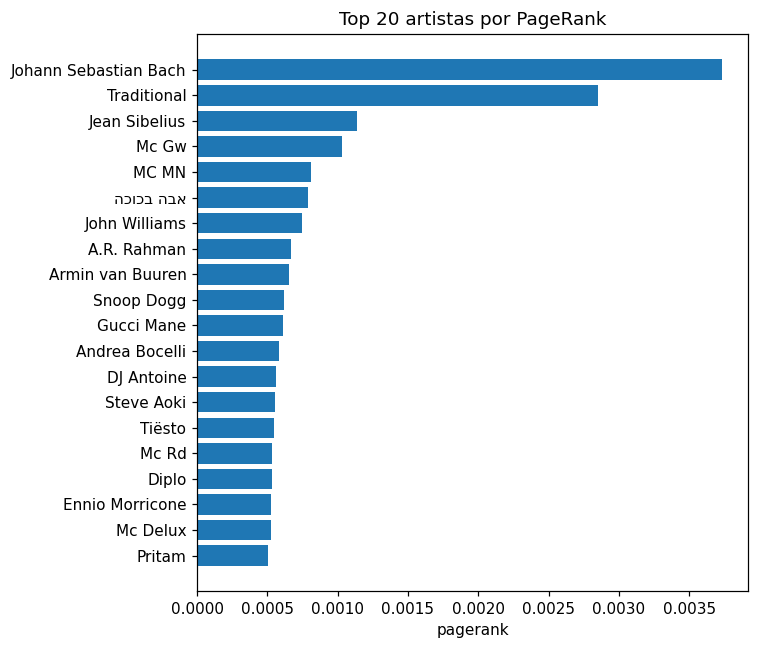

In [6]:
def barras(col, titulo, n=20, ax=None):
    t = nodes.nlargest(n, col)[::-1]
    ax = ax or plt.subplots(figsize=(7, 6))[1]
    ax.barh(t['name'], t[col])
    ax.set(title=titulo, xlabel=col)
    return ax

barras('pagerank', 'Top 20 artistas por PageRank'); plt.tight_layout(); plt.show()

### ¿El más central es también el más popular?

In [7]:
metricas = ['pagerank', 'grado', 'followers', 'popularity']
corr = nodes[metricas].corr(method='spearman')
corr.round(3)

,pagerank,grado,followers,popularity
pagerank,1.000,0.753,0.358,0.374
grado,0.753,1.000,0.503,0.538
followers,0.358,0.503,1.000,0.834
popularity,0.374,0.538,0.834,1.000


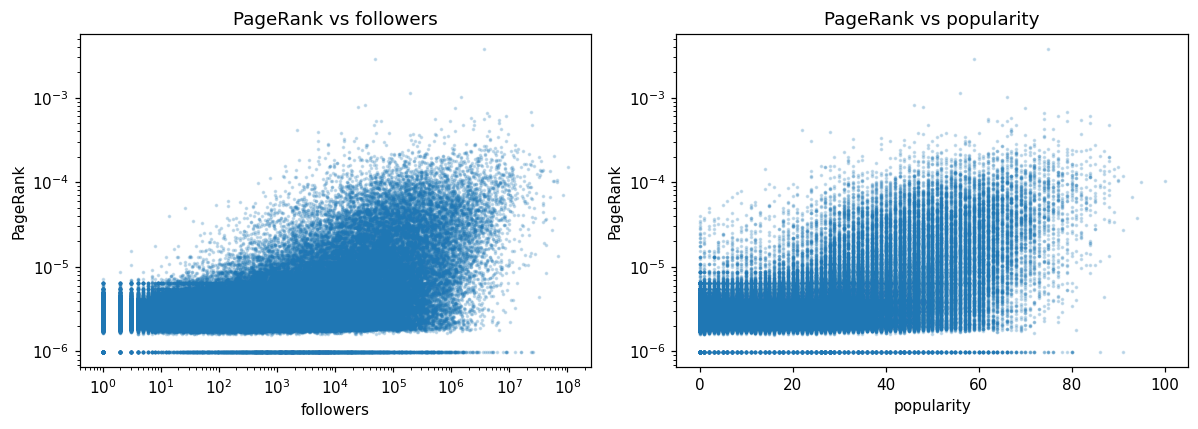

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, m in zip(axes, ['followers', 'popularity']):
    ax.scatter(nodes[m] + (1 if m == 'followers' else 0), nodes['pagerank'], s=2, alpha=.2)
    ax.set(xlabel=m, ylabel='PageRank', yscale='log',
           xscale='log' if m == 'followers' else 'linear', title=f'PageRank vs {m}')
plt.tight_layout(); plt.show()

## I.3. HITS (Hubs y Authorities)

HITS asigna a cada nodo dos puntajes:
- **Authority**: recibe enlaces de buenos hubs.
- **Hub**: apunta a buenas authorities.

### 3A. HITS sobre el grafo no dirigido

En un grafo **no dirigido**, la matriz de adyacencia es simétrica (`A = Aᵀ`), así que `AᵀA = AAᵀ = A²`. Hubs y authorities son el eigenvector principal de la **misma** matriz y por eso **salen idénticos**. Lo comprobamos:

In [9]:
hubs_u, auth_u = nx.hits(G, max_iter=1000, normalized=True)
nodes['hits_hub_nd'] = pd.Series(hubs_u)
nodes['hits_auth_nd'] = pd.Series(auth_u)
print('Diferencia máxima |hub - authority|:', (nodes.hits_hub_nd - nodes.hits_auth_nd).abs().max())
top('hits_auth_nd')

Diferencia máxima |hub - authority|: 2.3418766925686896e-17


,name,hits_auth_nd,grado,followers,popularity
spotify_id,,,,,
329e4yvIujISKGKz1BZZbO,Farruko,0.002605,284,13975050.0,84
6vXTefBL93Dj5IqAWq6OTv,French Montana,0.002330,320,4648251.0,76
13y7CgLHjMVRMDqxdx0Xdo,Gucci Mane,0.002224,509,4454550.0,77
7c0XG5cIJTrrAgEC3ULPiq,Ty Dolla $ign,0.002151,252,4339428.0,81
3EiLUeyEcA6fbRPSHkG5kb,De La Ghetto,0.002108,193,6242132.0,81
55Aa2cqylxrFIXC767Z865,Lil Wayne,0.002077,273,12587804.0,85
7bXgB6jMjp9ATFy66eO08Z,Chris Brown,0.002076,245,16868785.0,87
7hJcb9fa4alzcOq3EaNPoG,Snoop Dogg,0.002036,495,8686870.0,84
4SsVbpTthjScTS7U2hmr1X,Arcangel,0.002027,169,8825949.0,81


Además, HITS se **concentra** en la zona más densa de la red (el eigenvector principal de `A²` vive en el núcleo más conectado), mientras que PageRank reparte la importancia gracias al teletransporte. Por eso el top de HITS puede verse dominado por una sola "escena" musical.

### 3B. HITS sobre un grafo dirigido por popularidad

Para que hub y authority signifiquen cosas distintas le damos dirección a cada colaboración: **del artista menos popular al más popular** (el artista "chico" busca al "grande"). Los empates de popularidad se rompen por seguidores y, si persisten, la arista va en ambos sentidos.
- **Authority alta:** artista muy buscado por otros para colaborar.
- **Hub alto:** artista que colabora con muchos artistas más grandes que él.

In [10]:
rank = nodes[['popularity', 'followers']].apply(tuple, axis=1)
D = nx.DiGraph()
D.add_nodes_from(G)
for u, v in G.edges():
    ru, rv = rank[u], rank[v]
    if ru <= rv: D.add_edge(u, v)
    if rv <= ru: D.add_edge(v, u)
print(f'Aristas dirigidas: {D.number_of_edges():,}')

hubs_d, auth_d = nx.hits(D, max_iter=1000, normalized=True)
nodes['hits_hub_dir'] = pd.Series(hubs_d)
nodes['hits_auth_dir'] = pd.Series(auth_d)
top('hits_auth_dir', extra=['hits_hub_dir'])

Aristas dirigidas: 300,379


,name,hits_auth_dir,grado,followers,popularity,hits_hub_dir
spotify_id,,,,,,
5aIqB5nVVvmFsvSdExz408,Johann Sebastian Bach,0.699632,1781,3701532.0,75,-0.000000e+00
1U5zgr455OGyIkLNXvDdrf,Traditional,0.072576,1371,49046.0,59,5.372164e-04
7jzR5qj8vFnSu5JHaXgFEr,Jean Sibelius,0.027099,580,194098.0,56,3.755090e-06
3dRfiJ2650SZu6GbydcHNb,John Williams,0.010298,415,1154733.0,70,5.140019e-04
2qn4hIXsvRUyFoboMi31XB,Rolf Zuckowski,0.004981,72,99690.0,55,3.270076e-07
1nIUhcKHnK6iyumRyoV68C,Ennio Morricone,0.004367,276,940452.0,64,1.181021e-05
3EA9hVIzKfFiQI0Kikz2wo,Andrea Bocelli,0.003031,342,2221093.0,67,5.902795e-06
4NJhFmfw43RLBLjQvxDuRS,Wolfgang Amadeus Mozart,0.002636,12,4658811.0,75,-0.000000e+00
2VZNmg4vCnew4Pavo8zDdW,Max Richter,0.002604,83,795315.0,72,-0.000000e+00


In [11]:
top('hits_hub_dir', extra=['hits_auth_dir'])

,name,hits_hub_dir,grado,followers,popularity,hits_auth_dir
spotify_id,,,,,,
1GeaYVIXCzBwEbjAvv0NYn,Aled Jones,0.000620,143,13756.0,33,7.135454e-04
5IRFMGI8aEtZdN07OYrBZc,Tarja,0.000593,110,287728.0,45,6.082453e-04
2SHCkjATdUxGT429Uw4JPy,Arja Koriseva,0.000585,32,5943.0,29,4.119234e-04
395Z91yDQ05pkMbRKik18y,Franz Xaver Gruber,0.000580,82,1364.0,28,2.219250e-03
2jaOpr7Go1avixlg1lfJOb,Sissel,0.000576,42,46173.0,42,4.473695e-06
2FjkZT851ez950cyPjeYid,Bobby McFerrin,0.000570,24,182990.0,57,4.026783e-04
46T4yCHjQfVxokuATj1SiV,Tina Guo,0.000565,5,55948.0,47,-0.000000e+00
2MpxaqGTQeft5RU4wvwm57,Unknown,0.000564,8,9779.0,41,-0.000000e+00
0wMmGaXRfdHPhqSEAVQIr6,Instrumental,0.000563,4,57450.0,43,-0.000000e+00


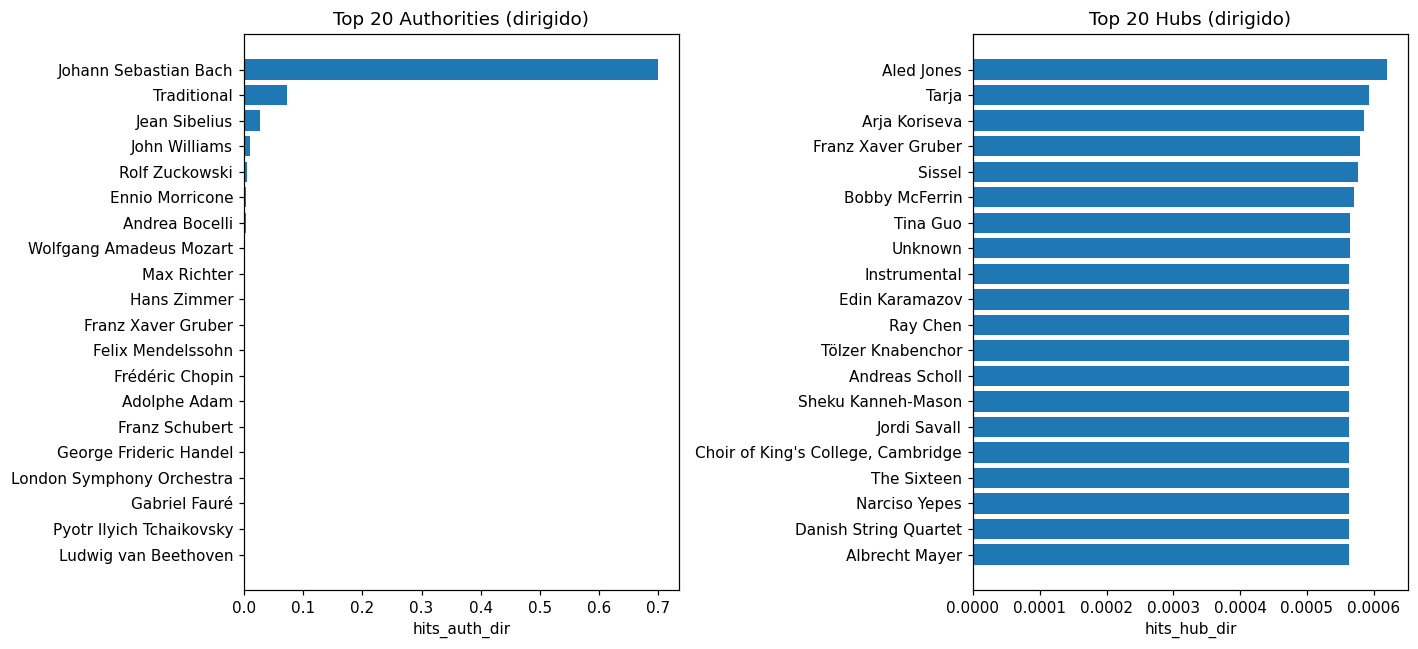

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
barras('hits_auth_dir', 'Top 20 Authorities (dirigido)', ax=axes[0])
barras('hits_hub_dir', 'Top 20 Hubs (dirigido)', ax=axes[1])
plt.tight_layout(); plt.show()

### Comparación PageRank vs HITS

In [13]:
cols = ['pagerank', 'hits_auth_nd', 'hits_auth_dir', 'hits_hub_dir', 'followers', 'popularity']
display(nodes[cols].corr(method='spearman').round(3))

def overlap(a, b, k=100):
    return len(set(nodes.nlargest(k, a).index) & set(nodes.nlargest(k, b).index))

for a, b in [('pagerank', 'hits_auth_nd'), ('pagerank', 'hits_auth_dir'),
             ('pagerank', 'hits_hub_dir'), ('hits_auth_dir', 'hits_hub_dir')]:
    print(f'Artistas en común en el top-100 de {a} y {b}: {overlap(a, b)}')

,pagerank,hits_auth_nd,hits_auth_dir,hits_hub_dir,followers,popularity
pagerank,1.000,-0.049,0.471,0.035,0.358,0.374
hits_auth_nd,-0.049,1.000,0.227,0.747,0.224,0.245
hits_auth_dir,0.471,0.227,1.000,0.108,0.453,0.470
hits_hub_dir,0.035,0.747,0.108,1.000,0.135,0.176
followers,0.358,0.224,0.453,0.135,1.000,0.834
popularity,0.374,0.245,0.470,0.176,0.834,1.000


Artistas en común en el top-100 de pagerank y hits_auth_nd: 17
Artistas en común en el top-100 de pagerank y hits_auth_dir: 17
Artistas en común en el top-100 de pagerank y hits_hub_dir: 2
Artistas en común en el top-100 de hits_auth_dir y hits_hub_dir: 7


## I.4. PageRank sensible a tópico (Topic-Sensitive PageRank)

En el PageRank normal el surfista se teletransporta a **cualquier** artista. En la versión sensible a tópico se teletransporta **solo a artistas del tópico**, con el vector de personalización `v` repartido uniformemente entre ellos. El resultado mide la importancia *desde la perspectiva* de ese género: artistas de otros géneros pueden subir si colaboran mucho con él.

**Tópicos:** reggaeton, k-pop, hip hop, pop, rock. Un artista pertenece al tópico si alguno de sus géneros **contiene** la palabra (p. ej. *"latin hip hop"* cuenta para hip hop; *"k-pop"* también cuenta para pop).

In [14]:
topicos = ['reggaeton', 'k-pop', 'hip hop', 'pop', 'rock']
miembros = {t: nodes.index[nodes.genres.apply(lambda gs: any(t in g for g in gs))] for t in topicos}
for t, m in miembros.items():
    print(f'{t:10s}: {len(m):6,} artistas en el conjunto de teletransporte')

for t, m in miembros.items():
    nodes[f'tspr_{t}'] = pd.Series(nx.pagerank(G, alpha=0.85, personalization={n: 1 for n in m}))

reggaeton :    607 artistas en el conjunto de teletransporte
k-pop     :    438 artistas en el conjunto de teletransporte
hip hop   :  8,179 artistas en el conjunto de teletransporte
pop       : 18,171 artistas en el conjunto de teletransporte
rock      :  4,208 artistas en el conjunto de teletransporte


In [15]:
nodes['rank_pr'] = nodes.pagerank.rank(ascending=False).astype(int)

for t in topicos:
    col = f'tspr_{t}'
    tbl = nodes.nlargest(10, col)[['name', col, 'rank_pr', 'genres']].copy()
    tbl['del_tópico'] = tbl.index.isin(miembros[t])
    tbl['genres'] = tbl.genres.apply(lambda g: ', '.join(g[:3]))
    print(f'\n=== Top 10 — {t.upper()} ===  (rank_pr = posición en el PageRank general)')
    display(tbl)


=== Top 10 — REGGAETON ===  (rank_pr = posición en el PageRank general)


,name,tspr_reggaeton,rank_pr,genres,del_tópico
spotify_id,,,,,
12vb80Km0Ew53ABfJOepVz,Ñengo Flow,0.005190,91,"latin hip hop, reggaeton, reggaeton flow",True
329e4yvIujISKGKz1BZZbO,Farruko,0.003621,84,"latin hip hop, reggaeton, trap latino",True
6XFITTl7cFTdopDY3lUdlY,J Alvarez,0.003552,199,"latin hip hop, reggaeton, reggaeton flow",True
1GKIlPFdcewHtpDVCQ8zmJ,Brray,0.003176,251,"reggaeton, reggaeton flow, trap latino",True
2ydZrTy8U3kOMOzx20s3dg,DJ Nelson,0.003140,209,"latin hip hop, reggaeton, reggaeton flow",True
2dYSrA999b3VYp5V4J12T7,Sixto Rein,0.002947,457,"pop reggaeton, pop venezolano",True
00me4Ke1LsvMxt5kydlMyU,Cosculluela,0.002781,644,"latin hip hop, reggaeton, reggaeton flow",True
4SsVbpTthjScTS7U2hmr1X,Arcangel,0.002738,445,"latin hip hop, reggaeton, trap latino",True
62lbdm09j0QUbWB7SqCJvt,Anonimus,0.002678,253,"perreo, reggaeton, reggaeton flow",True



=== Top 10 — K-POP ===  (rank_pr = posición en el PageRank general)


,name,tspr_k-pop,rank_pr,genres,del_tópico
spotify_id,,,,,
3HqSLMAZ3g3d5poNaI7GOU,IU,0.004245,2361,k-pop,True
5snNHNlYT2UrtZo5HCJkiw,Epik High,0.004048,334,"k-pop, k-rap, korean old school hip hop",True
30b9WulBM8sFuBo17nNq9c,G-DRAGON,0.003509,3112,"k-pop, k-rap",True
2u7CP5T30c8ctenzXgEV1W,pH-1,0.003024,1793,"k-pop, k-rap, korean r&b",True
63cvWayCvPbWYNDi537w0z,DINDIN,0.002998,1249,korean r&b,False
2MtHuR0W2idZdF7x4wddqq,GIRIBOY,0.002830,727,"k-rap, korean r&b",False
4XDi67ZENZcbfKnvMnTYsI,Jay Park,0.002801,359,"k-pop, k-rap, korean r&b",True
7pXKdkQsYFCMG2omRxheJ2,Basick,0.002751,612,k-rap,False
6aLdhHUqgdKE86xbtNmY8g,Crush,0.002698,1842,"k-pop, korean r&b",True



=== Top 10 — HIP HOP ===  (rank_pr = posición en el PageRank general)


,name,tspr_hip hop,rank_pr,genres,del_tópico
spotify_id,,,,,
13y7CgLHjMVRMDqxdx0Xdo,Gucci Mane,0.001132,11,"atl hip hop, dirty south rap, gangster rap",True
6UBA15slIuadJ8h2lPRPos,Tech N9ne,0.000983,68,"hip hop, kansas city hip hop, pop rap",True
7hJcb9fa4alzcOq3EaNPoG,Snoop Dogg,0.000868,10,"g funk, gangster rap, hip hop",True
4AA474G2hRfrHyGrfyDseO,Mozzy,0.000850,26,"cali rap, pop rap, rap",True
56n1NeXsTOOxjX3Z4lVMTJ,SFDK,0.000833,361,"rap politico, rap underground espanol, spanish hip hop",True
7GaMopkesD4KK9dNbgyO5D,Eko Fresh,0.000674,45,"cologne hip hop, deep german hip hop, german hip hop",True
7f35VZGDpomj11PXdNn5D9,Max B,0.000624,49,trap,False
4sfpwybxbvBBio0eOkESLG,P3,0.000620,56,ohio hip hop,True
6f4XkbvYlXMH0QgVRzW0sM,Waka Flocka Flame,0.000613,22,"atl hip hop, dirty south rap, gangster rap",True



=== Top 10 — POP ===  (rank_pr = posición en el PageRank general)


,name,tspr_pop,rank_pr,genres,del_tópico
spotify_id,,,,,
01pSsqt7FLdq2SC6UqjER3,Raimonds Pauls,0.000612,47,"classic latvian pop, latvian pop",True
2o5jDhtHVPhrJdv3cEQ99Z,Tiësto,0.000559,15,"big room, brostep, dance pop",True
6cEuCEZu7PAE9ZSzLLc2oQ,R3HAB,0.000554,27,"dance pop, dutch house, edm",True
77AiFEVeAVj2ORpC85QVJs,Steve Aoki,0.000551,14,"dance pop, edm, electro house",True
5fMUXHkw8R8eOP2RNVYEZX,Diplo,0.000532,17,"edm, electro house, moombahton",True
1mYsTxnqsietFxj1OgoGbG,A.R. Rahman,0.000518,8,"desi pop, filmi, modern bollywood",True
1U5zgr455OGyIkLNXvDdrf,Traditional,0.000518,2,"puirt-a-beul, sleep",False
1wRPtKGflJrBx9BmLsSwlU,Pritam,0.000510,20,"desi pop, filmi, indian instrumental",True
7hJcb9fa4alzcOq3EaNPoG,Snoop Dogg,0.000498,10,"g funk, gangster rap, hip hop",True



=== Top 10 — ROCK ===  (rank_pr = posición en el PageRank general)


,name,tspr_rock,rank_pr,genres,del_tópico
spotify_id,,,,,
5aIqB5nVVvmFsvSdExz408,Johann Sebastian Bach,0.004146,1,"baroque, classical, early music",False
1U5zgr455OGyIkLNXvDdrf,Traditional,0.002046,2,"puirt-a-beul, sleep",False
1k5aZWIOUbUfKcnMxtEivJ,Jimmy Barnes,0.001176,682,"australian pop, australian rock",True
5VX8hxrcfJWwaTLiqGUHG3,TobyMac,0.000987,442,"ccm, christian alternative rock, christian hip hop",True
1db5TWniHR7iqwXer7AiQ2,Pappo,0.000979,2388,"argentine heavy metal, argentine rock, latin alternative",True
32vWCbZh0xZ4o9gkz4PsEU,Dolly Parton,0.000959,402,"classic country pop, country, country dawn",False
3SXDCIdqI1AR686ukKtKCq,Bi-2,0.000953,162,"belarusian pop, belarusian rock, classic russian rock",True
7jzR5qj8vFnSu5JHaXgFEr,Jean Sibelius,0.000876,3,"classical, finnish classical, impressionism",False
6kACVPfCOnqzgfEF5ryl0x,Johnny Cash,0.000848,1040,"arkansas country, outlaw country",False


### Artistas *externos* que el tópico eleva
Artistas que **no** pertenecen al género, pero que tienen alto puntaje en él por colaborar con sus artistas: son los *puentes* entre escenas.

In [16]:
for t in topicos:
    col = f'tspr_{t}'
    fuera = nodes.drop(miembros[t]).nlargest(5, col)
    print(f'{t:10s} ->', ', '.join(fuera.name))

reggaeton  -> Johann Sebastian Bach, Redimi2, Rauw Alejandro, Traditional, Pablo Chill-E
k-pop      -> DINDIN, GIRIBOY, Basick, MC MONG, Paloalto
hip hop    -> Max B, Fumez The Engineer, Diplo, Wyclef Jean, Steve Aoki
pop        -> Traditional, Moby, DJ Hamida, Raffa Affar, George Dalaras
rock       -> Johann Sebastian Bach, Traditional, Dolly Parton, Jean Sibelius, Johnny Cash


### Heatmap: importancia de los artistas en cada tópico
Tomamos el top 5 de cada tópico y normalizamos cada columna (puntaje / máximo del tópico).

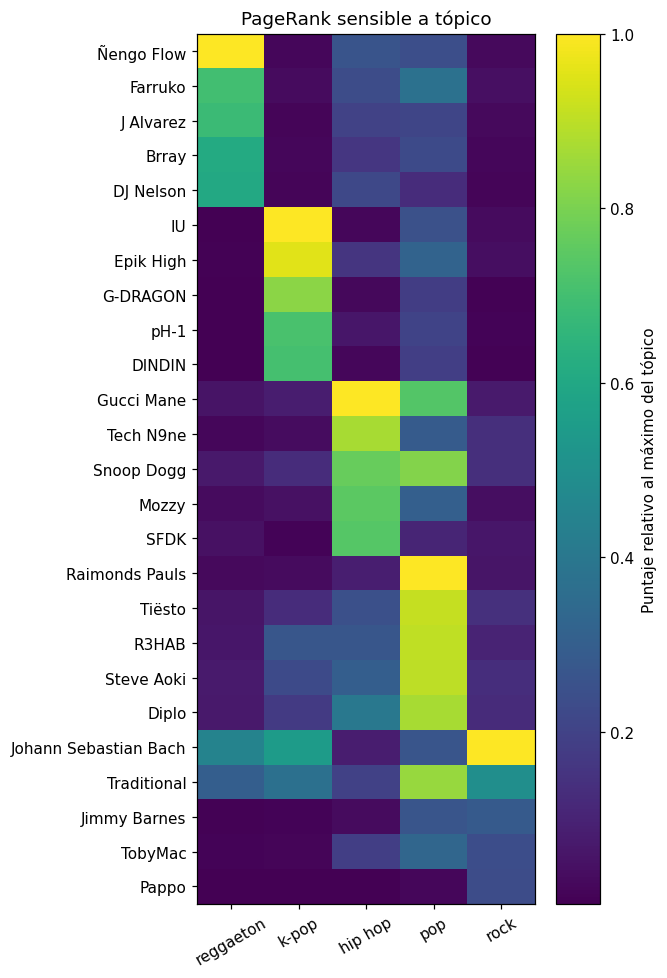

In [17]:
tcols = [f'tspr_{t}' for t in topicos]
sel = pd.unique(np.concatenate([nodes.nlargest(5, c).index for c in tcols]))
H = nodes.loc[sel, tcols]
H = H / nodes[tcols].max()
H.index = nodes.loc[sel, 'name']; H.columns = topicos

fig, ax = plt.subplots(figsize=(6, 9))
im = ax.imshow(H.values, cmap='viridis', aspect='auto')
ax.set_xticks(range(len(topicos)), topicos, rotation=30)
ax.set_yticks(range(len(H)), H.index)
fig.colorbar(im, label='Puntaje relativo al máximo del tópico')
ax.set_title('PageRank sensible a tópico')
plt.tight_layout(); plt.show()

In [18]:
# ¿Qué tanto cambia cada ranking por tópico respecto al PageRank general?
pd.Series({t: spearmanr(nodes.pagerank, nodes[f'tspr_{t}']).statistic for t in topicos},
          name='Spearman vs PageRank general').round(3).to_frame()

,Spearman vs PageRank general
reggaeton,0.373
k-pop,0.440
hip hop,0.636
pop,0.723
rock,0.499


## I.5. Conclusiones

1. **Estructura de la red.** Es una red libre de escala que tiene 156,320 artistas, 300,379 colaboraciones y un grado promedio de apenas 3.84, pero con nodos de hasta 1,781 colaboradores. El 94.9 % de los artistas está en una sola componente gigante.

2. **Un sesgo del dataset.** Los nodos más centrales son *Johann Sebastian Bach*, *Traditional* y *Jean Sibelius*. No son colaboradores en un sentido real sino que Spotify los acredita como compositores en miles de grabaciones de otros intérpretes. Esto infla su grado y afecta a todos los algoritmos.

3. **PageRank** está muy correlacionado con el grado (Spearman 0.75) y solo moderadamente con seguidores (0.36) y popularidad (0.37). Ser central en la red de colaboraciones no significa ser el más escuchado, ya que en el top aparecen DJs/productores (Armin van Buuren, Steve Aoki, Tiësto, Diplo), compositores de cine (John Williams, A.R. Rahman) y MCs brasileños de funk (Mc Gw, MC MN), pero no Ed Sheeran ni Ariana Grande.

4. **HITS no dirigido.** Como predice la teoría (`AᵀA = AAᵀ`), hub = authority (diferencia máxima ≈ 6·10⁻¹⁷). HITS se concentra en el núcleo más denso, el **reggaeton/trap latino y el hip hop estadounidense** (Farruko, French Montana, Gucci Mane, J Balvin...). Su correlación con PageRank es prácticamente nula (−0.05) ya que PageRank mide alcance global y HITS mide pertenencia al bloque más denso.

5. **HITS dirigido por popularidad.** El authority se concentra casi por completo en Bach (0.70) y en la música clásica, y los hubs son intérpretes clásicos (coros, cuartetos, solistas) que "colaboran" con compositores muy populares. Aun así, la authority dirigida es la métrica que más se correlaciona con la popularidad (0.47), porque por construcción las aristas apuntan hacia los artistas populares. HITS es muy sensible a una comunidad densa (el efecto *Tightly Knit Community*).

6. **PageRank sensible a tópico.** Cada tópico reordena el ranking hacia sus referentes, por ejemplo IU y G-DRAGON en k-pop, que en el PageRank general ocupan las posiciones 2,361 y 3,112. También eleva artistas puente que no tienen la etiqueta del tópico (DINDIN y GIRIBOY, con *korean r&b*, en k-pop; Diplo y Wyclef Jean en hip hop). Los tópicos de nicho se alejan más del ranking general (Spearman: reggaeton 0.37, k-pop 0.44) que los amplios (hip hop 0.64, pop 0.72), porque sus conjuntos de teletransporte son más pequeños y cohesionados. En *rock*, Bach y Traditional siguen arriba ya que su grado enorme los hace accesibles desde casi cualquier tópico.



#  II. Red de citas de física de altas energías (arXiv HEP-PH)

**Dataset:** *High-energy physics citation network* (SNAP, Stanford: `cit-HepPh`).
- `cit-HepPh.txt`: aristas dirigidas `A → B` = el artículo A **cita** al artículo B (enero 1993 – abril 2003).
- `cit-HepPh-dates.txt`: fecha de publicación de cada artículo en arXiv.

**Objetivo:** encontrar los artículos más importantes de la red con PageRank, HITS y PageRank sensible a tópico, y comparar los resultados entre sí y con el número de citas.

A diferencia de la red de Spotify, esta red **sí es dirigida**: una cita tiene un sentido claro. Por eso HITS tiene una interpretación natural:
- **Authority:** artículo fundamental, citado por buenos hubs.
- **Hub:** artículo que cita a muchas buenas authorities, normalmente una revisión (*review*).

## II.1. Carga y limpieza de datos

In [19]:
edges = pd.read_csv('cit-HepPh.txt', sep='\t', comment='#', names=['src', 'dst'])
fechas = pd.read_csv('cit-HepPh-dates.txt', sep='\t', comment='#', names=['id', 'fecha'], dtype={'id': str})
print('Aristas crudas:', len(edges), '| Fechas crudas:', len(fechas))

# Los IDs de arXiv tienen 7 dígitos (AAMMNNN). En el archivo de aristas son enteros (se pierden los
# ceros a la izquierda) y en el de fechas los artículos 'cross-listed' llevan el prefijo '11'.
# Normalizamos todo a entero y, si hay varias fechas para un artículo, nos quedamos con la más antigua.
fechas['id'] = fechas['id'].apply(lambda s: int(s[2:]) if len(s) > 7 else int(s))
fechas['fecha'] = pd.to_datetime(fechas['fecha'])
fecha = fechas.groupby('id')['fecha'].min()

autocitas = (edges.src == edges.dst).sum()
edges = edges[edges.src != edges.dst].drop_duplicates()
print(f'Autocitas eliminadas: {autocitas} | Aristas limpias: {len(edges):,}')

Aristas crudas: 421578 | Fechas crudas: 38557
Autocitas eliminadas: 44 | Aristas limpias: 421,534


In [20]:
G = nx.DiGraph()
G.add_edges_from(edges.itertuples(index=False, name=None))

papers = pd.DataFrame(index=pd.Index(sorted(G.nodes()), name='paper'))
papers['arxiv'] = ['hep-ph/' + str(p).zfill(7) for p in papers.index]   # buscar en arxiv.org/abs/<arxiv>
papers['fecha'] = fecha.reindex(papers.index)
papers['año'] = papers.fecha.dt.year
papers['citas'] = pd.Series(dict(G.in_degree()))         # veces que es citado
papers['referencias'] = pd.Series(dict(G.out_degree()))  # artículos que cita

wcc = sorted(nx.weakly_connected_components(G), key=len, reverse=True)
print(f'Artículos: {G.number_of_nodes():,}  Citas: {G.number_of_edges():,}')
print(f'Artículos con fecha: {papers.fecha.notna().sum():,} ({papers.fecha.notna().mean():.1%})')
print(f'Citas promedio por artículo: {papers.citas.mean():.2f}  Máximo: {papers.citas.max()}')
print(f'Artículos que no citan a nadie dentro de la red (dangling): {(papers.referencias == 0).sum():,}')
print(f'Artículos nunca citados: {(papers.citas == 0).sum():,}')
print(f'Componentes débilmente conexas: {len(wcc)}  Componente gigante: {len(wcc[0]):,} '
      f'({len(wcc[0]) / G.number_of_nodes():.1%})')
print(f'Pares que se citan mutuamente: {sum(G.has_edge(v, u) for u, v in G.edges()) // 2:,}')

t = edges.assign(f_src=edges.src.map(fecha), f_dst=edges.dst.map(fecha)).dropna()
print(f'Citas "al futuro" (el citado es posterior al que cita): {(t.f_src < t.f_dst).sum():,} '
      f'de {len(t):,}; se deben a versiones revisadas de los artículos')

Artículos: 34,546  Citas: 421,534
Artículos con fecha: 30,561 (88.5%)
Citas promedio por artículo: 12.20  Máximo: 846
Artículos que no citan a nadie dentro de la red (dangling): 2,393
Artículos nunca citados: 6,320
Componentes débilmente conexas: 61  Componente gigante: 34,401 (99.6%)
Pares que se citan mutuamente: 657
Citas "al futuro" (el citado es posterior al que cita): 2,344 de 347,288; se deben a versiones revisadas de los artículos


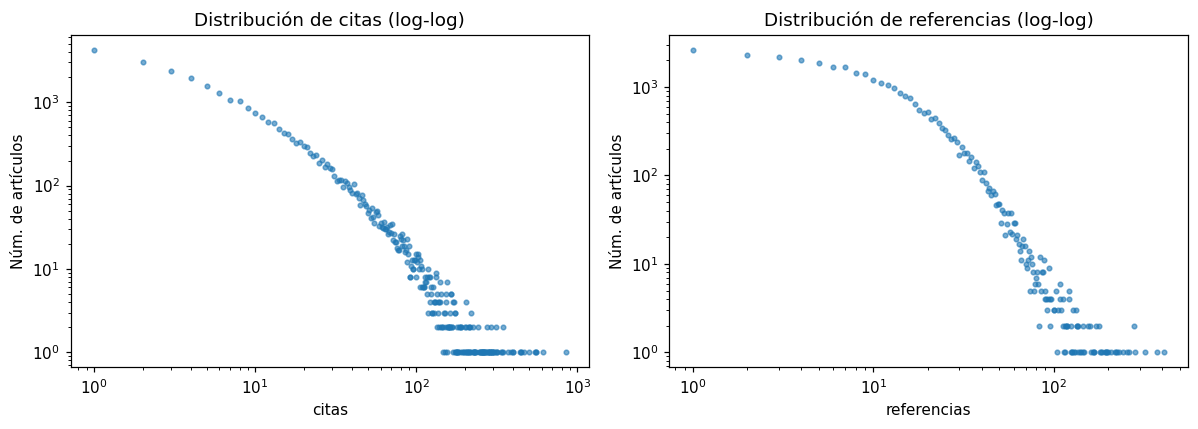

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, col in zip(axes, ['citas', 'referencias']):
    cnt = papers[col][papers[col] > 0].value_counts().sort_index()
    ax.loglog(cnt.index, cnt.values, '.', alpha=.6)
    ax.set(xlabel=col, ylabel='Núm. de artículos', title=f'Distribución de {col} (log-log)')
plt.tight_layout(); plt.show()

La distribución de **citas** (grado de entrada) tiene cola pesada: pocos artículos acumulan cientos de citas. La de **referencias** (grado de salida) es más acotada, porque un artículo cita a un número limitado de trabajos.

## II.2. PageRank

El surfista aleatorio va de artículo en artículo **siguiendo citas** y con probabilidad `1 - α` (α = 0.85) salta a un artículo al azar. Un artículo es importante si lo citan artículos importantes. En los nodos *dangling* (que no citan a nadie de la red), networkx reparte su peso uniformemente entre todos los nodos.

In [22]:
papers['pagerank'] = pd.Series(nx.pagerank(G, alpha=0.85))

def top(col, n=20, extra=()):
    return papers.nlargest(n, col)[['arxiv', col, 'citas', 'referencias', 'año', *extra]]

top('pagerank')

,arxiv,pagerank,citas,referencias,año
paper,,,,,
9303255,hep-ph/9303255,0.003657,154,0,1993.0
9209205,hep-ph/9209205,0.002754,343,0,1992.0
9310316,hep-ph/9310316,0.002505,106,0,1993.0
9206203,hep-ph/9206203,0.002258,32,0,1992.0
9208254,hep-ph/9208254,0.002168,67,0,1992.0
9803315,hep-ph/9803315,0.001836,846,0,1998.0
9203203,hep-ph/9203203,0.001756,217,0,1992.0
9206242,hep-ph/9206242,0.001755,140,0,1992.0
9303230,hep-ph/9303230,0.001667,347,1,1993.0


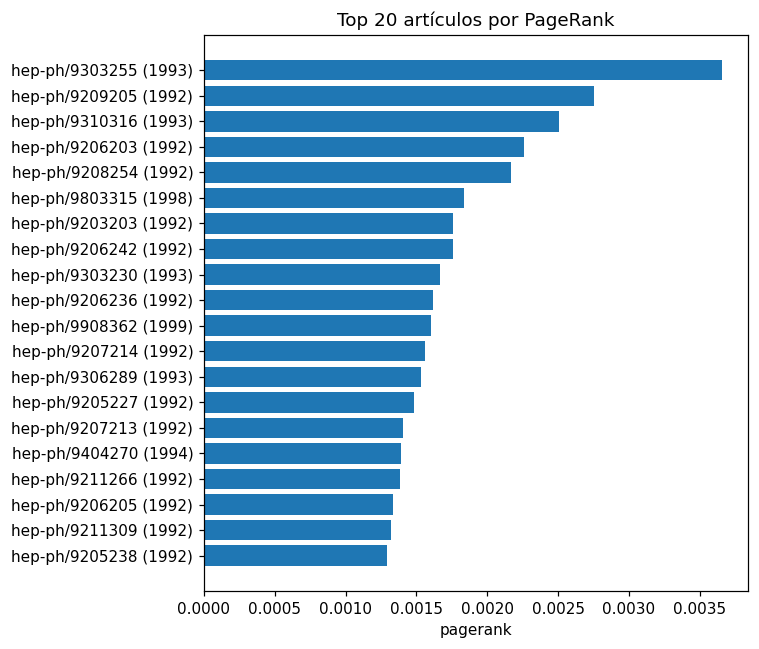

In [23]:
def barras(col, titulo, n=20, ax=None):
    t = papers.nlargest(n, col)[::-1]
    ax = ax or plt.subplots(figsize=(7, 6))[1]
    etiquetas = [f'{a} ({int(y) if pd.notna(y) else "s/f"})' for a, y in zip(t.arxiv, t.año)]
    ax.barh(etiquetas, t[col])
    ax.set(title=titulo, xlabel=col)
    return ax

barras('pagerank', 'Top 20 artículos por PageRank'); plt.tight_layout(); plt.show()

### PageRank vs número de citas y antigüedad

In [24]:
papers[['pagerank', 'citas', 'referencias', 'año']].corr(method='spearman').round(3)

,pagerank,citas,referencias,año
pagerank,1.000,0.910,-0.068,-0.380
citas,0.910,1.000,0.165,-0.183
referencias,-0.068,0.165,1.000,0.463
año,-0.380,-0.183,0.463,1.000


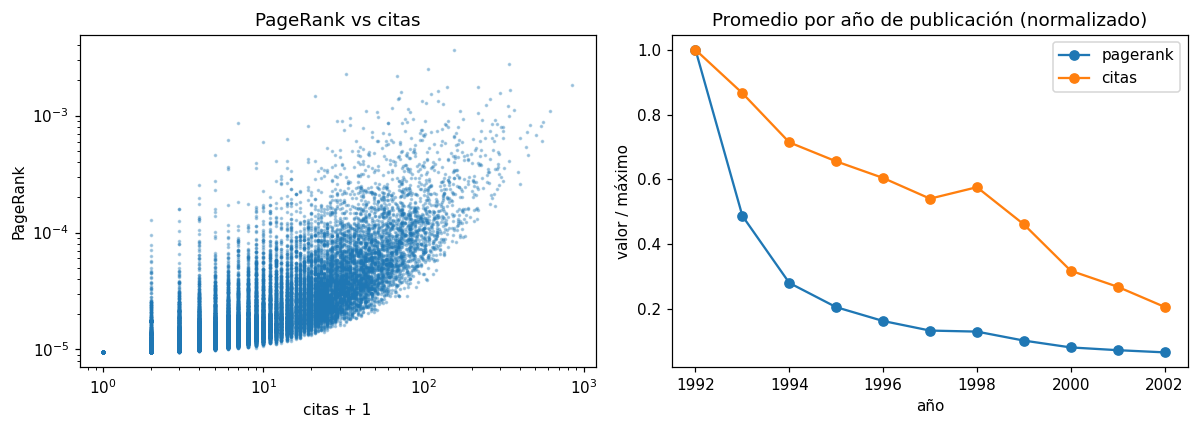

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(papers.citas + 1, papers.pagerank, s=2, alpha=.3)
axes[0].set(xscale='log', yscale='log', xlabel='citas + 1', ylabel='PageRank', title='PageRank vs citas')
por_año = papers.dropna(subset=['año']).groupby('año')[['pagerank', 'citas']].mean()
(por_año / por_año.max()).plot(ax=axes[1], marker='o',
    title='Promedio por año de publicación (normalizado)')
axes[1].set_ylabel('valor / máximo')
plt.tight_layout(); plt.show()

Los artículos **antiguos** tienen en promedio más PageRank y más citas: llevan más tiempo en la red para ser citados, y por construcción una cita casi siempre apunta hacia el pasado. Es el **sesgo temporal** típico de las redes de citas.

## II.3. HITS (Hubs y Authorities)

### 3A. HITS sobre el grafo dirigido (la versión natural)

In [26]:
hubs, auth = nx.hits(G, max_iter=1000, normalized=True)
papers['hits_hub'] = pd.Series(hubs).clip(lower=0)  # quita ceros numéricos negativos (-1e-20)
papers['hits_auth'] = pd.Series(auth).clip(lower=0)
top('hits_auth', extra=['hits_hub'])

,arxiv,hits_auth,citas,referencias,año,hits_hub
paper,,,,,,
9803315,hep-ph/9803315,0.013207,846,0,1998.0,-0.000000
9804398,hep-ph/9804398,0.010754,616,6,1998.0,0.000232
9807344,hep-ph/9807344,0.009269,503,7,1998.0,0.000398
9811291,hep-ph/9811291,0.006326,286,24,1998.0,0.000677
9905221,hep-ph/9905221,0.006081,449,16,1999.0,0.000758
9811350,hep-ph/9811350,0.005822,255,16,1998.0,0.000660
9803466,hep-ph/9803466,0.005586,305,3,1998.0,0.000192
9811337,hep-ph/9811337,0.005446,219,9,1998.0,0.000518
9806292,hep-ph/9806292,0.005136,289,14,1998.0,0.000385


In [27]:
top('hits_hub', extra=['hits_auth'])

,arxiv,hits_hub,citas,referencias,año,hits_auth
paper,,,,,,
9909232,hep-ph/9909232,0.001809,38,109,1999.0,0.000831
204031,hep-ph/0204031,0.001781,3,229,NaN,0.000020
8333,hep-ph/0008333,0.001771,16,94,2000.0,0.000317
6190,hep-ph/0006190,0.001522,5,80,2000.0,0.000089
9906431,hep-ph/9906431,0.001495,25,66,1999.0,0.000696
9909377,hep-ph/9909377,0.001475,9,78,1999.0,0.000245
205106,hep-ph/0205106,0.001421,12,77,NaN,0.000186
9910255,hep-ph/9910255,0.001417,22,78,1999.0,0.000501
9912279,hep-ph/9912279,0.001393,6,70,1999.0,0.000028


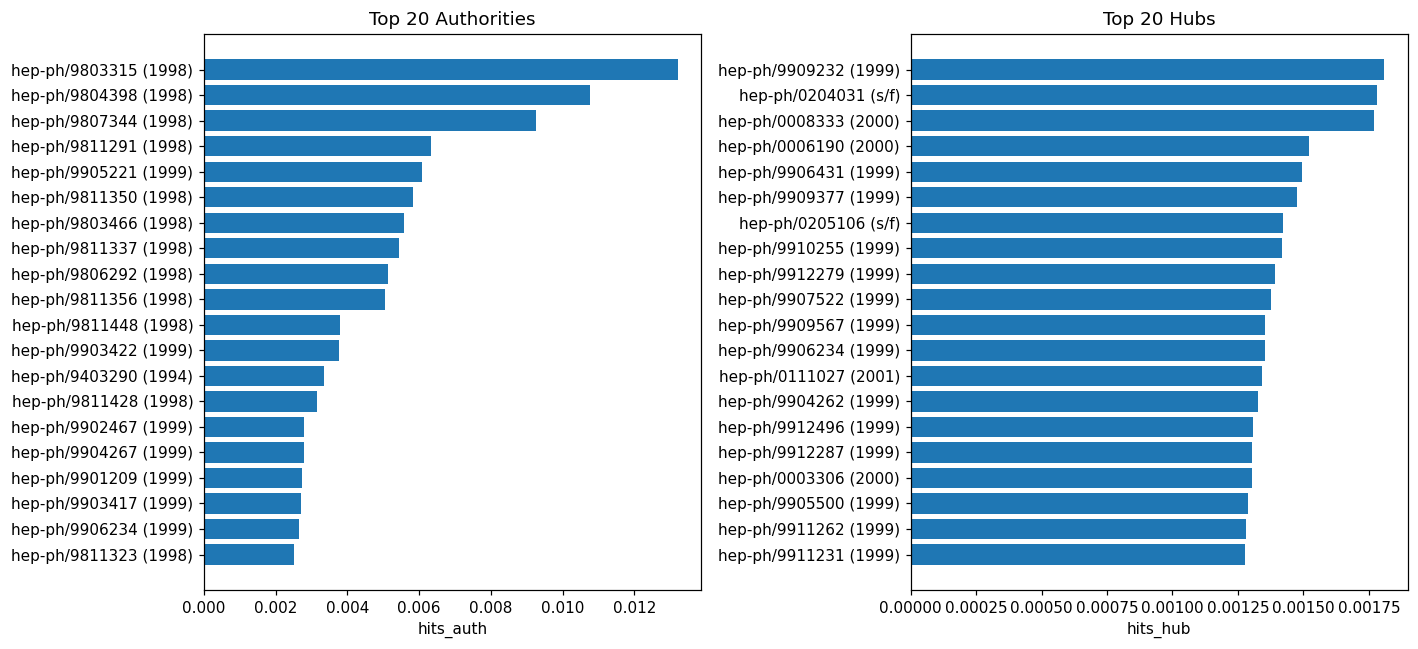

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
barras('hits_auth', 'Top 20 Authorities', ax=axes[0])
barras('hits_hub', 'Top 20 Hubs', ax=axes[1])
plt.tight_layout(); plt.show()

### 3B. HITS sobre el grafo no dirigido (para comparar con Spotify)

Si ignoramos la dirección de las citas, la matriz de adyacencia es simétrica y, igual que en la red de Spotify, **hub = authority**.

In [29]:
hubs_u, auth_u = nx.hits(G.to_undirected(), max_iter=1000, normalized=True)
papers['hits_nd'] = pd.Series(auth_u)
print('Diferencia máxima |hub - authority| (no dirigido):', (pd.Series(hubs_u) - pd.Series(auth_u)).abs().max())
top('hits_nd', n=10)

Diferencia máxima |hub - authority| (no dirigido): 2.6020852139652106e-18


,arxiv,hits_nd,citas,referencias,año
paper,,,,,
9803315,hep-ph/9803315,0.002943,846,0,1998.0
9804398,hep-ph/9804398,0.002451,616,6,1998.0
9807344,hep-ph/9807344,0.002179,503,7,1998.0
9811291,hep-ph/9811291,0.001679,286,24,1998.0
9811350,hep-ph/9811350,0.001534,255,16,1998.0
9803466,hep-ph/9803466,0.001515,305,3,1998.0
9905221,hep-ph/9905221,0.001452,449,16,1999.0
9811337,hep-ph/9811337,0.001411,219,9,1998.0
9806292,hep-ph/9806292,0.001403,289,14,1998.0


### Comparación PageRank vs HITS

In [30]:
cols = ['pagerank', 'hits_auth', 'hits_hub', 'hits_nd', 'citas', 'referencias', 'año']
display(papers[cols].corr(method='spearman').round(3))

def overlap(a, b, k=100):
    return len(set(papers.nlargest(k, a).index) & set(papers.nlargest(k, b).index))

for a, b in [('pagerank', 'citas'), ('pagerank', 'hits_auth'), ('hits_auth', 'citas'),
             ('hits_hub', 'referencias'), ('pagerank', 'hits_hub'), ('hits_auth', 'hits_hub')]:
    print(f'Artículos en común en el top-100 de {a:9s} y {b}: {overlap(a, b)}')

,pagerank,hits_auth,hits_hub,hits_nd,citas,referencias,año
pagerank,1.000,0.666,-0.009,0.257,0.910,-0.068,-0.380
hits_auth,0.666,1.000,0.481,0.726,0.832,0.294,-0.053
hits_hub,-0.009,0.481,1.000,0.873,0.214,0.770,0.320
hits_nd,0.257,0.726,0.873,1.000,0.465,0.608,0.124
citas,0.910,0.832,0.214,0.465,1.000,0.165,-0.183
referencias,-0.068,0.294,0.770,0.608,0.165,1.000,0.463
año,-0.380,-0.053,0.320,0.124,-0.183,0.463,1.000


Artículos en común en el top-100 de pagerank  y citas: 32
Artículos en común en el top-100 de pagerank  y hits_auth: 8
Artículos en común en el top-100 de hits_auth y citas: 27
Artículos en común en el top-100 de hits_hub  y referencias: 7
Artículos en común en el top-100 de pagerank  y hits_hub: 0
Artículos en común en el top-100 de hits_auth y hits_hub: 23


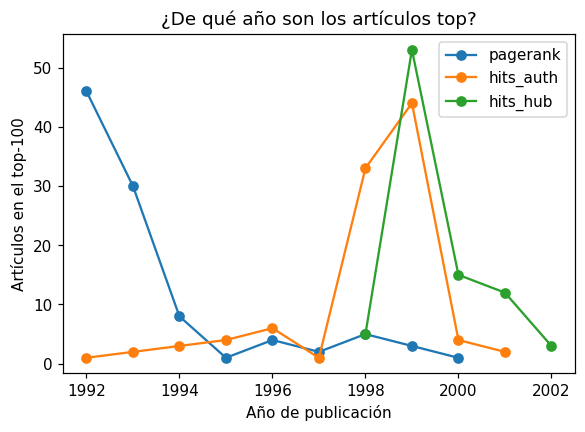

In [31]:
fig, ax = plt.subplots(figsize=(6, 4))
for col in ['pagerank', 'hits_auth', 'hits_hub']:
    t = papers.nlargest(100, col).año.value_counts().sort_index()
    ax.plot(t.index, t.values, marker='o', label=col)
ax.set(xlabel='Año de publicación', ylabel='Artículos en el top-100', title='¿De qué año son los artículos top?')
ax.legend(); plt.show()

## II.4. PageRank sensible a tópico (Topic-Sensitive PageRank)

Este dataset **no trae la temática** de cada artículo (no hay títulos ni categorías). Definimos los tópicos de dos maneras:

1. **Tópicos por comunidad.** Detectamos comunidades con el algoritmo de **Louvain** sobre el grafo de citas (sin dirección). Artículos que se citan mucho entre sí suelen tratar el mismo subtema, así que cada comunidad aproxima un *tópico de investigación*. Usamos las 5 comunidades más grandes.
2. **Tópicos por época.** Teletransportamos solo a artículos publicados en un periodo, con lo que medimos qué artículos eran importantes *desde el punto de vista* de la investigación de esa época.

En ambos casos el vector de personalización `v` se reparte uniformemente entre los artículos del tópico.

In [32]:
comunidades = sorted(nx.community.louvain_communities(G.to_undirected(), seed=42), key=len, reverse=True)
print(f'Comunidades encontradas: {len(comunidades)}')

topicos = {}
for i, c in enumerate(comunidades[:5], 1):
    sub = papers.loc[list(c)]
    ancla = sub.citas.idxmax()
    nombre = f'C{i}'
    topicos[nombre] = sub.index
    print(f'{nombre}: {len(c):5,} artículos | año mediano {sub.año.median():.0f} | '
          f'artículo más citado: {papers.arxiv[ancla]} ({papers.citas[ancla]} citas)')

papers['comunidad'] = None
for nombre, idx in topicos.items():
    papers.loc[idx, 'comunidad'] = nombre

Comunidades encontradas: 83
C1: 4,393 artículos | año mediano 1998 | artículo más citado: hep-ph/9606399 (542 citas)
C2: 4,117 artículos | año mediano 1998 | artículo más citado: hep-ph/9512380 (550 citas)
C3: 3,895 artículos | año mediano 1998 | artículo más citado: hep-ph/9807216 (399 citas)
C4: 3,862 artículos | año mediano 1997 | artículo más citado: hep-ph/9408384 (444 citas)
C5: 3,239 artículos | año mediano 1997 | artículo más citado: hep-ph/9502298 (273 citas)


In [33]:
def tspr(miembros):
    return pd.Series(nx.pagerank(G, alpha=0.85, personalization={n: 1 for n in miembros}))

for t, m in topicos.items():
    papers[f'tspr_{t}'] = tspr(m)

papers['rank_pr'] = papers.pagerank.rank(ascending=False).astype(int)
for t in topicos:
    col = f'tspr_{t}'
    tbl = papers.nlargest(10, col)[['arxiv', col, 'rank_pr', 'citas', 'año', 'comunidad']]
    print(f'\n=== Top 10 — tópico {t} ===  (rank_pr = posición en el PageRank general)')
    display(tbl)


=== Top 10 — tópico C1 ===  (rank_pr = posición en el PageRank general)


,arxiv,tspr_C1,rank_pr,citas,año,comunidad
paper,,,,,,
9209205,hep-ph/9209205,0.014252,2,343,1992.0,C1
9303255,hep-ph/9303255,0.010440,1,154,1993.0,C1
9212206,hep-ph/9212206,0.004662,28,43,1992.0,None
9406315,hep-ph/9406315,0.004567,22,244,1994.0,C1
9208249,hep-ph/9208249,0.004336,34,51,1992.0,C1
9410404,hep-ph/9410404,0.004181,26,369,1994.0,C1
9302225,hep-ph/9302225,0.004083,60,164,1993.0,C1
9205213,hep-ph/9205213,0.003838,63,41,1992.0,C1
9207228,hep-ph/9207228,0.003784,35,34,1992.0,C1



=== Top 10 — tópico C2 ===  (rank_pr = posición en el PageRank general)


,arxiv,tspr_C2,rank_pr,citas,año,comunidad
paper,,,,,,
9207214,hep-ph/9207214,0.008598,12,301,1992.0,C2
9908362,hep-ph/9908362,0.007305,11,71,1999.0,C2
9304225,hep-ph/9304225,0.007276,23,338,1993.0,C2
9205221,hep-ph/9205221,0.005352,37,85,1992.0,C2
9211248,hep-ph/9211248,0.005242,65,95,1992.0,C2
9308246,hep-ph/9308246,0.004735,61,314,1993.0,C2
9209268,hep-ph/9209268,0.004594,64,130,1992.0,C2
9206241,hep-ph/9206241,0.004590,49,72,1992.0,C2
9204237,hep-ph/9204237,0.004527,57,18,1992.0,C2



=== Top 10 — tópico C3 ===  (rank_pr = posición en el PageRank general)


,arxiv,tspr_C3,rank_pr,citas,año,comunidad
paper,,,,,,
9207213,hep-ph/9207213,0.009269,15,69,1992.0,C3
9206242,hep-ph/9206242,0.007704,8,140,1992.0,None
9306212,hep-ph/9306212,0.006544,46,78,1993.0,C3
9203213,hep-ph/9203213,0.006212,48,6,1992.0,C3
9212204,hep-ph/9212204,0.006070,54,34,1992.0,C3
9311214,hep-ph/9311214,0.005775,62,141,1993.0,C3
9807216,hep-ph/9807216,0.004802,88,399,1998.0,C3
9204215,hep-ph/9204215,0.004388,47,59,1992.0,C3
9311306,hep-ph/9311306,0.004369,108,64,1993.0,C3



=== Top 10 — tópico C4 ===  (rank_pr = posición en el PageRank general)


,arxiv,tspr_C4,rank_pr,citas,año,comunidad
paper,,,,,,
9206203,hep-ph/9206203,0.010404,4,32,1992.0,C4
9303230,hep-ph/9303230,0.007383,9,347,1993.0,C4
9205227,hep-ph/9205227,0.006371,14,20,1992.0,C4
9211266,hep-ph/9211266,0.005677,17,68,1992.0,C4
9207219,hep-ph/9207219,0.005182,41,30,1992.0,C4
9207234,hep-ph/9207234,0.005130,40,232,1992.0,C4
9210235,hep-ph/9210235,0.004068,39,279,1992.0,C4
9307201,hep-ph/9307201,0.004039,98,166,1993.0,C4
9209232,hep-ph/9209232,0.003978,33,340,1992.0,C4



=== Top 10 — tópico C5 ===  (rank_pr = posición en el PageRank general)


,arxiv,tspr_C5,rank_pr,citas,año,comunidad
paper,,,,,,
9205238,hep-ph/9205238,0.008398,20,103,1992.0,C5
9204214,hep-ph/9204214,0.005498,82,98,1992.0,C5
9204204,hep-ph/9204204,0.004509,115,59,1992.0,C5
9310210,hep-ph/9310210,0.004136,167,56,1993.0,C5
9502298,hep-ph/9502298,0.004126,107,273,1995.0,C5
9212285,hep-ph/9212285,0.003990,90,83,1992.0,C5
9206205,hep-ph/9206205,0.003769,18,97,1992.0,C5
9303236,hep-ph/9303236,0.003759,207,39,1993.0,C5
9307371,hep-ph/9307371,0.003718,104,50,1993.0,C5


### Artículos *externos* que el tópico eleva
Artículos que **no** pertenecen a la comunidad pero que reciben alto puntaje desde ella: trabajos fundamentales que comparten varios subtemas.

In [34]:
for t, m in topicos.items():
    fuera = papers.drop(m).nlargest(5, f'tspr_{t}')
    print(f'{t} ->', ', '.join(fuera.arxiv + ' [' + fuera.comunidad.fillna('otra') + ']'))

C1 -> hep-ph/9212206 [otra], hep-ph/9310316 [otra], hep-ph/9901214 [C5], hep-ph/9402283 [otra], hep-ph/9305228 [otra]
C2 -> hep-ph/9212203 [otra], hep-ph/9304257 [otra], hep-ph/9206205 [C5], hep-ph/9211304 [otra], hep-ph/9208254 [otra]
C3 -> hep-ph/9206242 [otra], hep-ph/9203206 [otra], hep-ph/9206205 [C5], hep-ph/9206203 [C4], hep-ph/9203201 [otra]
C4 -> hep-ph/9203220 [C3], hep-ph/9303255 [C1], hep-ph/9211256 [C2], hep-ph/9204225 [C3], hep-ph/9211260 [C2]
C5 -> hep-ph/9303255 [C1], hep-ph/9206236 [otra], hep-ph/9302250 [otra], hep-ph/9610447 [otra], hep-ph/9401258 [C4]


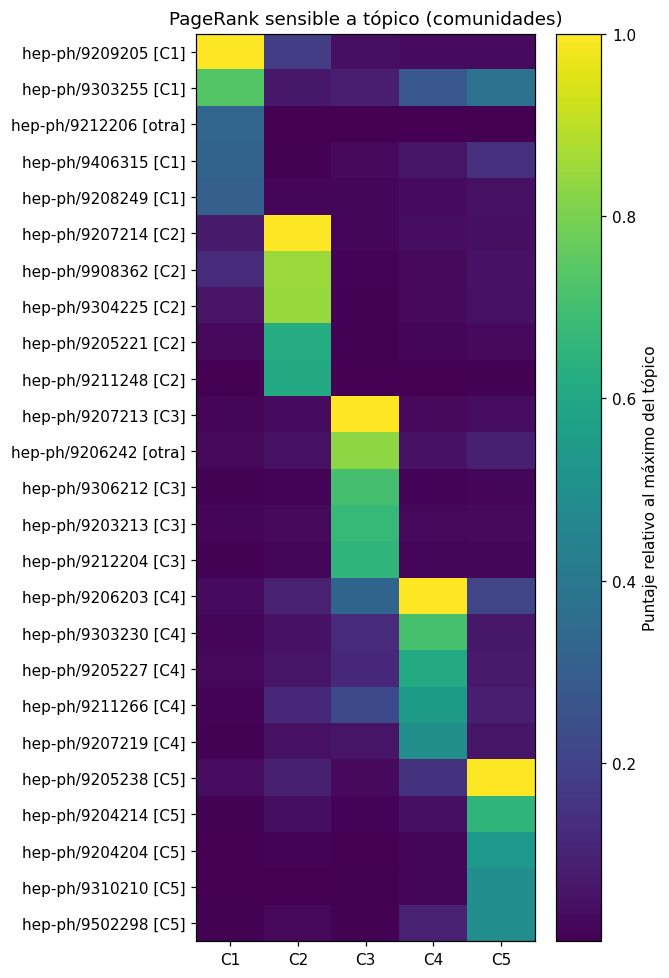

In [35]:
tcols = [f'tspr_{t}' for t in topicos]
sel = pd.unique(np.concatenate([papers.nlargest(5, c).index for c in tcols]))
H = papers.loc[sel, tcols] / papers[tcols].max()
H.index = papers.loc[sel, 'arxiv'] + ' [' + papers.loc[sel, 'comunidad'].fillna('otra') + ']'
H.columns = list(topicos)

fig, ax = plt.subplots(figsize=(6, 9))
im = ax.imshow(H.values, cmap='viridis', aspect='auto')
ax.set_xticks(range(len(topicos)), list(topicos))
ax.set_yticks(range(len(H)), H.index)
fig.colorbar(im, label='Puntaje relativo al máximo del tópico')
ax.set_title('PageRank sensible a tópico (comunidades)')
plt.tight_layout(); plt.show()

In [36]:
pd.Series({t: spearmanr(papers.pagerank, papers[f'tspr_{t}']).statistic for t in topicos},
          name='Spearman vs PageRank general').round(3).to_frame()

,Spearman vs PageRank general
C1,0.640
C2,0.654
C3,0.658
C4,0.654
C5,0.682


### Tópicos por época

In [37]:
epocas = {'1992-1995': (1992, 1995), '1996-1998': (1996, 1998), '1999-2002': (1999, 2002)}
for e, (a, b) in epocas.items():
    papers[f'tspr_{e}'] = tspr(papers.index[papers.año.between(a, b)])

for e in epocas:
    col = f'tspr_{e}'
    print(f'\n=== Top 10 — época {e} ===')
    display(papers.nlargest(10, col)[['arxiv', col, 'rank_pr', 'citas', 'año']])


=== Top 10 — época 1992-1995 ===


,arxiv,tspr_1992-1995,rank_pr,citas,año
paper,,,,,
9303255,hep-ph/9303255,0.005043,1,154,1993.0
9206203,hep-ph/9206203,0.004639,4,32,1992.0
9203203,hep-ph/9203203,0.004623,7,217,1992.0
9310316,hep-ph/9310316,0.003930,3,106,1993.0
9208254,hep-ph/9208254,0.003698,5,67,1992.0
9206242,hep-ph/9206242,0.002917,8,140,1992.0
9205238,hep-ph/9205238,0.002911,20,103,1992.0
9209205,hep-ph/9209205,0.002713,2,343,1992.0
9203220,hep-ph/9203220,0.002602,24,63,1992.0



=== Top 10 — época 1996-1998 ===


,arxiv,tspr_1996-1998,rank_pr,citas,año
paper,,,,,
9303255,hep-ph/9303255,0.004475,1,154,1993.0
9209205,hep-ph/9209205,0.003178,2,343,1992.0
9310316,hep-ph/9310316,0.002941,3,106,1993.0
9208254,hep-ph/9208254,0.002507,5,67,1992.0
9206203,hep-ph/9206203,0.002301,4,32,1992.0
9303230,hep-ph/9303230,0.002204,9,347,1993.0
9306289,hep-ph/9306289,0.001925,13,110,1993.0
9404270,hep-ph/9404270,0.001914,16,259,1994.0
9206242,hep-ph/9206242,0.001889,8,140,1992.0



=== Top 10 — época 1999-2002 ===


,arxiv,tspr_1999-2002,rank_pr,citas,año
paper,,,,,
9803315,hep-ph/9803315,0.003012,6,846,1998.0
9303255,hep-ph/9303255,0.002829,1,154,1993.0
9209205,hep-ph/9209205,0.002570,2,343,1992.0
9310316,hep-ph/9310316,0.001901,3,106,1993.0
9804398,hep-ph/9804398,0.001839,27,616,1998.0
9211309,hep-ph/9211309,0.001838,19,122,1992.0
9206203,hep-ph/9206203,0.001617,4,32,1992.0
9208254,hep-ph/9208254,0.001576,5,67,1992.0
9206242,hep-ph/9206242,0.001444,8,140,1992.0


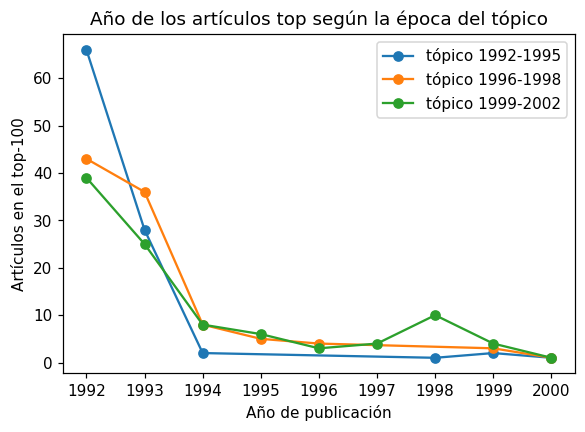

In [38]:
fig, ax = plt.subplots(figsize=(6, 4))
for e in epocas:
    t = papers.nlargest(100, f'tspr_{e}').año.value_counts().sort_index()
    ax.plot(t.index, t.values, marker='o', label=f'tópico {e}')
ax.set(xlabel='Año de publicación', ylabel='Artículos en el top-100',
       title='Año de los artículos top según la época del tópico')
ax.legend(); plt.show()

## II.5. Conclusiones

1. **Estructura de la red.** 34,546 artículos y 421,534 citas, con 12.2 citas por artículo en promedio y un máximo de 846. El 99.6 % de los artículos está en una sola componente. Detalles de limpieza: quitamos 44 autocitas, 11.5 % de los artículos no tiene fecha (sobre todo los de 2002–2003) y hay 2,344 citas "al futuro", que vienen de versiones revisadas de los artículos.

2. **PageRank ≈ citas, con sesgo hacia lo antiguo.** PageRank se correlaciona muy fuerte con el número de citas (Spearman 0.91), pero **negativamente con el año** (−0.38). El top está dominado por artículos de 1992–1993 que **no citan a nadie dentro de la red**, porque son los primeros del dataset. Las citas siempre apuntan al pasado, así que el surfista aleatorio termina acumulándose en los artículos más viejos. Por eso un artículo con solo 32 citas (`hep-ph/9206203`) queda en 4.º lugar: lo citan artículos que a su vez son muy importantes.

3. **HITS dirigido encuentra una comunidad concreta.** Las authorities son casi todas de **1998–1999**: `hep-ph/9803315` (846 citas, el más citado del dataset), `9804398`, `9807344`, `9905221`… Son los artículos fundacionales de **dimensiones extra** (ADD y Randall–Sundrum; puedes verificarlo en arxiv.org/abs/hep-ph/9803315). Los hubs son artículos de 1999–2001 con muchísimas referencias (hasta 229), es decir, **revisiones**. Es el efecto *Tightly Knit Community*: HITS se concentra en el subtema más denso y "de moda", mientras que PageRank premia la antigüedad. Por eso solo comparten **8 artículos** en sus top-100.

4. **Hub y authority sí son distintos en un grafo dirigido.** El hub se correlaciona con las referencias (0.77) y el authority con las citas (0.83). En cambio, si quitamos la dirección, hub = authority (diferencia ≈ 3·10⁻¹⁸), igual que en Spotify. Es la misma prueba teórica (`AᵀA = AAᵀ`) en otra red.

5. **PageRank sensible a tópico.**
   - **Por comunidad (Louvain):** cada una de las 5 comunidades tiene sus propios artículos clave, que en el ranking general ocupan posiciones como 82, 115 o 167, y además aparecen artículos "puente" de otras comunidades. Todas se parecen al ranking general en grado similar (Spearman 0.64–0.68), porque el sesgo temporal pesa más que la comunidad.
   - **Por época:** aunque el surfista empiece en artículos de 1999–2002, vuelve a llegar a los clásicos de 1992–93, porque las citas viajan hacia atrás. Aun así, el tópico 1999–2002 **sube a `hep-ph/9803315` al 1.er lugar** y a `9804398` del puesto 27 al 5.º. Es decir, la física de esa época giraba alrededor de las dimensiones extra.

# Comparación final entre ambas redes

En Spotify (no dirigida) HITS sin dirección no distingue roles, y para separarlos tuvimos que inventar una dirección. Aquí la dirección es natural y HITS separa claramente **artículos fundacionales** de **revisiones**. En ambas redes PageRank y HITS miden cosas diferentes (alcance global contra núcleo denso), y en ambas el PageRank por tópico revela referentes y puentes que el ranking general oculta.
